# Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"Bengaluru_House_Data_Cleaned.csv")

In [3]:
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bedrooms,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,1.0,39.07,2,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,3.0,120.00,4,4615.384615
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,3.0,62.00,3,4305.555556
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,1.0,95.00,3,6245.890861
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,1.0,51.00,2,4250.000000


In [4]:
df.count()

area_type         12733
availability      12733
location          12733
size              12733
total_sqft        12733
bath              12733
balcony           12733
price             12733
bedrooms          12733
price_per_sqft    12733
dtype: int64

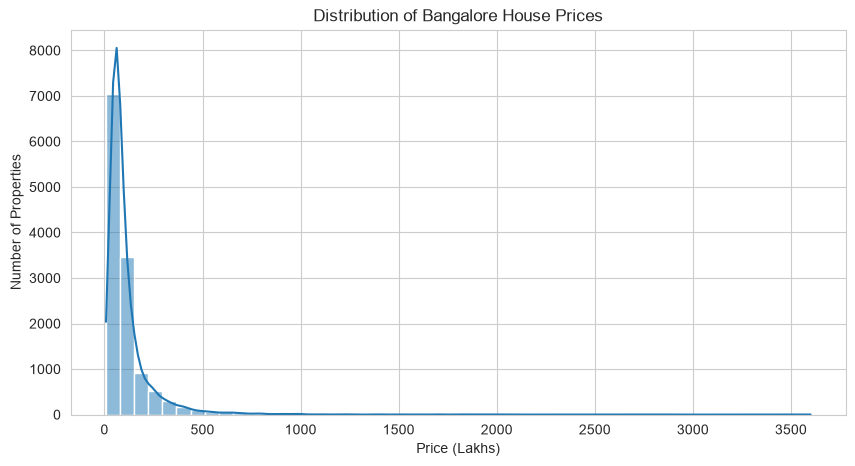

In [5]:
# Analysis 1: Understand the property price distribution
plt.figure(figsize=(10, 5))

sns.set_style("whitegrid")

sns.histplot(data = df, x = "price", bins=50, kde=True)

plt.title("Distribution of Bangalore House Prices")
plt.xlabel("Price (Lakhs)")
plt.ylabel("Number of Properties")

plt.show()

Most Bangalore properties are priced below ₹200 lakhs (₹2 crore). The distribution is highly right-skewed, with a few properties exceeding ₹500 lakhs (₹5 crore) and a maximum price of approximately ₹3,600 lakhs (₹36 crore).

In [7]:
df["price"].agg(["mean", "median", "min", "max"])

mean       112.641438
median      70.000000
min          9.000000
max       2912.000000
Name: price, dtype: float64

In [8]:
df["bedrooms"].value_counts().sort_index()

bedrooms
1      624
2     5167
3     4533
4     1238
5      202
6       90
7       42
8       25
9       14
10       5
11       2
13       1
16       1
Name: count, dtype: Int64

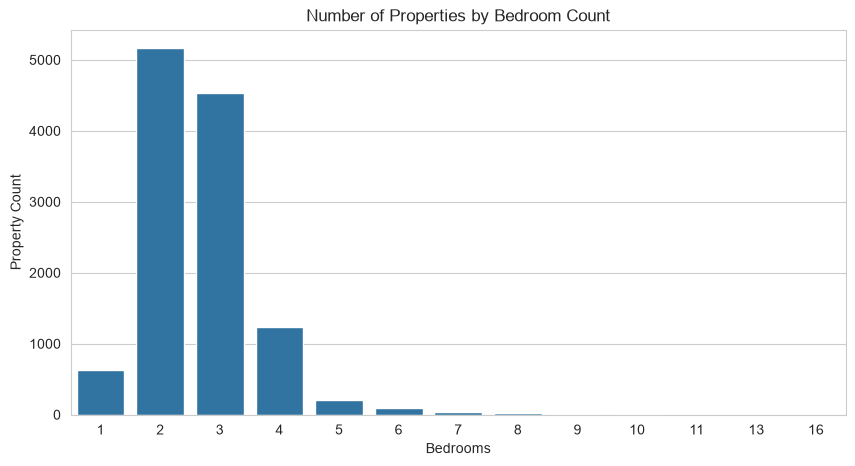

In [9]:
# Analysis 2: Identify the most common property sizes
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="bedrooms")

plt.title("Number of Properties by Bedroom Count")
plt.xlabel("Bedrooms")
plt.ylabel("Property Count")

plt.show()

2-bedroom properties are the most common (~5,150 listings), followed by 3-bedroom (~4,500) and 4-bedroom (~1,200) properties. Properties with 5+ bedrooms are significantly less common.

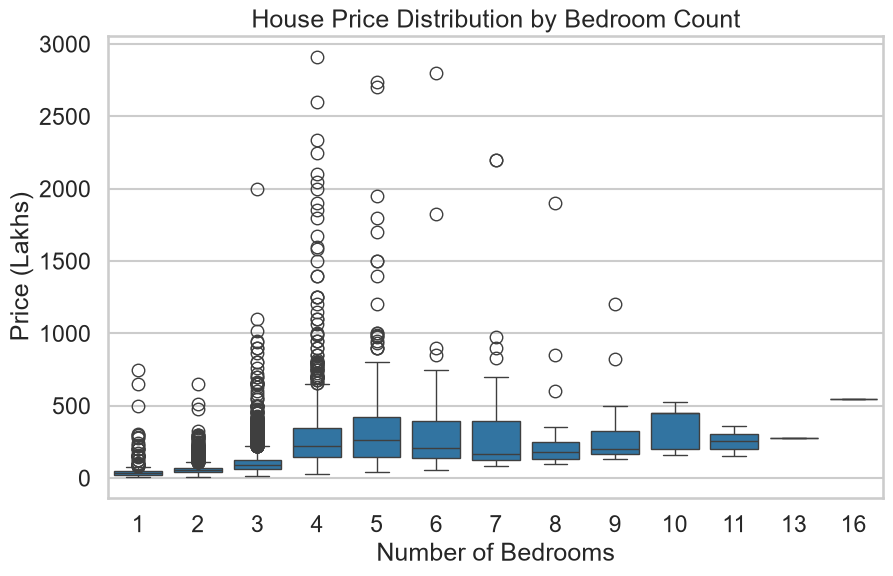

In [10]:
# Analysis 3: Compare prices by bedroom count
plt.figure(figsize=(10, 6))

sns.set_context("talk")

sns.boxplot(data=df, x="bedrooms", y="price")

plt.title("House Price Distribution by Bedroom Count")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (Lakhs)")

plt.show()

2-bedroom properties have median prices below ₹50 lakhs, while 3-bedroom properties are around ₹100 lakhs. 4–6-bedroom properties show higher median prices and greater variability, with outliers reaching approximately ₹2,900 lakhs (₹29 crore).

In [11]:
# Analysis 4: Find the locations with the most listings
top_locations = df["location"].value_counts().head(15)

print(top_locations)

location
Whitefield                  520
Sarjapur Road               373
Electronic City             280
Kanakpura Road              238
Thanisandra                 229
Yelahanka                   204
Marathahalli                164
Hebbal                      160
Raja Rajeshwari Nagar       158
Uttarahalli                 148
Bannerghatta Road           147
Hennur Road                 145
7th Phase JP Nagar          129
Electronic City Phase II    122
Rajaji Nagar                100
Name: count, dtype: int64


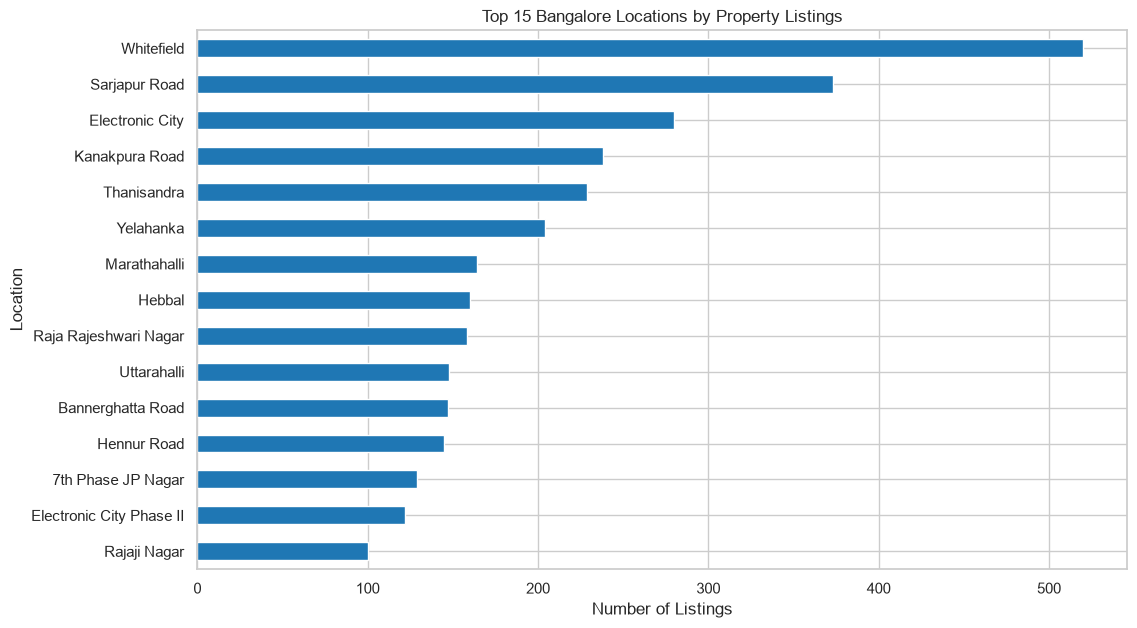

In [16]:
plt.figure(figsize=(12, 7))

top_locations.sort_values().plot(kind="barh")

plt.title("Top 15 Bangalore Locations by Property Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Location")

plt.show()

Whitefield has the highest number of listings (520), followed by Sarjapur Road (373) and Electronic City (280). These locations have the strongest property listing presence in the dataset.

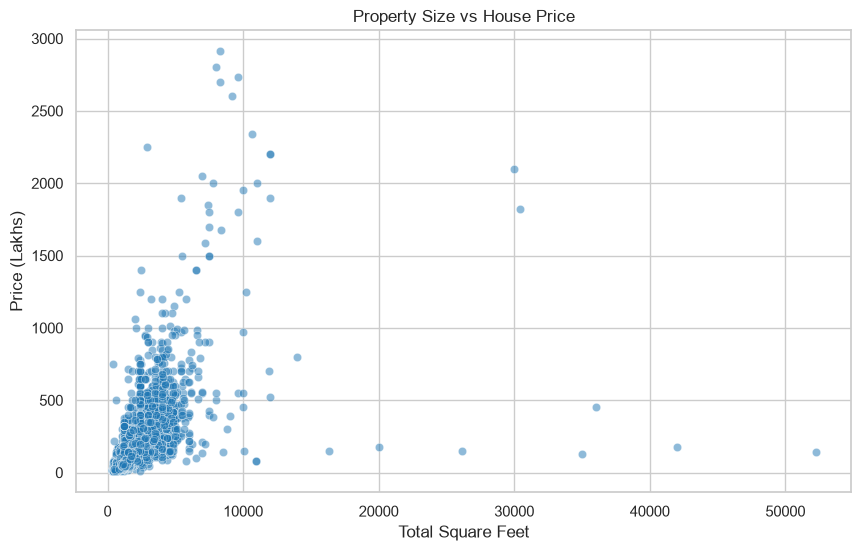

In [13]:
# Analysis 5: Does property size relate to price?
plt.figure(figsize=(10, 6))

sns.set_context("notebook")

sns.scatterplot(
    data=df,
    x="total_sqft",
    y="price",
    alpha=0.5
)

plt.title("Property Size vs House Price")
plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")

plt.show()

Property prices generally increase with size, but the relationship is not consistent. Most properties are below 10,000 sq. ft. and ₹500 lakhs, with outliers exceeding 50,000 sq. ft. and ₹2,900 lakhs (₹29 crore).

In [14]:
# Analysis 6: investigate relationships between numerical variables.
numerical_columns = [
    "total_sqft",
    "bath",
    "balcony",
    "bedrooms",
    "price",
    "price_per_sqft"
]

correlation = df[numerical_columns].corr()

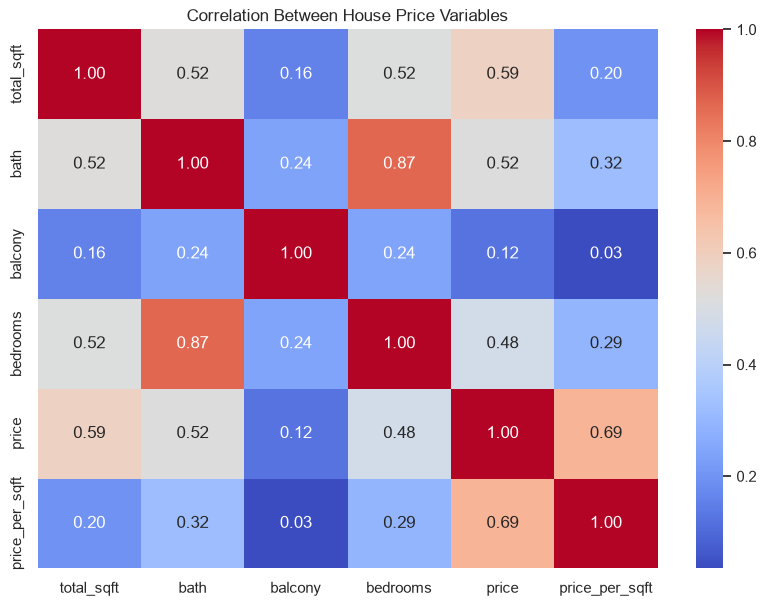

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between House Price Variables")

plt.show()

Property price has the strongest correlation with price per sq. ft. (0.69), followed by total area (0.59), bathrooms (0.52), and bedrooms (0.48). Bathrooms and bedrooms are highly correlated (0.87), while balconies have a weak correlation with price (0.12).